# Exercise 2 — Computer Vision: Image Blending Using OpenCV

## Objective
Load two images, resize them to identical dimensions, blend them using `cv2.addWeighted`, and save/display both inputs and the composite output.

The two supplied sample images are illustrative images created for this exercise. You may replace them with your own images while keeping the filenames or updating the paths below.

In [1]:
# If required, install OpenCV in the active Jupyter environment:
# %pip install opencv-python matplotlib

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\fmsch\assignment")
IMAGE_DIR = PROJECT_DIR / "Exercise2_DhruvRawat"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
image1_path = IMAGE_DIR / "image1.jpg"
image2_path = IMAGE_DIR / "image2.jpg"

image1 = cv2.imread(str(image1_path))
image2 = cv2.imread(str(image2_path))

if image1 is None or image2 is None:
    raise FileNotFoundError("Could not load image1.jpg or image2.jpg. Check the file paths.")

print("Original image 1 dimensions:", image1.shape)
print("Original image 2 dimensions:", image2.shape)

Original image 1 dimensions: (420, 640, 3)
Original image 2 dimensions: (420, 640, 3)


In [2]:
# Resize the second image to match the first image's width and height.
height, width = image1.shape[:2]
image2_resized = cv2.resize(image2, (width, height), interpolation=cv2.INTER_AREA)

# Weighted blend: 60% image 1 + 40% image 2.
blended = cv2.addWeighted(image1, 0.6, image2_resized, 0.4, 0)

output_path = IMAGE_DIR / "blended_image.jpg"
if not cv2.imwrite(str(output_path), blended):
    raise IOError("Blended image could not be saved.")

print("Blended image saved to:", output_path.resolve())

Blended image saved to: C:\Users\fmsch\assignment\Exercise2_DhruvRawat\blended_image.jpg


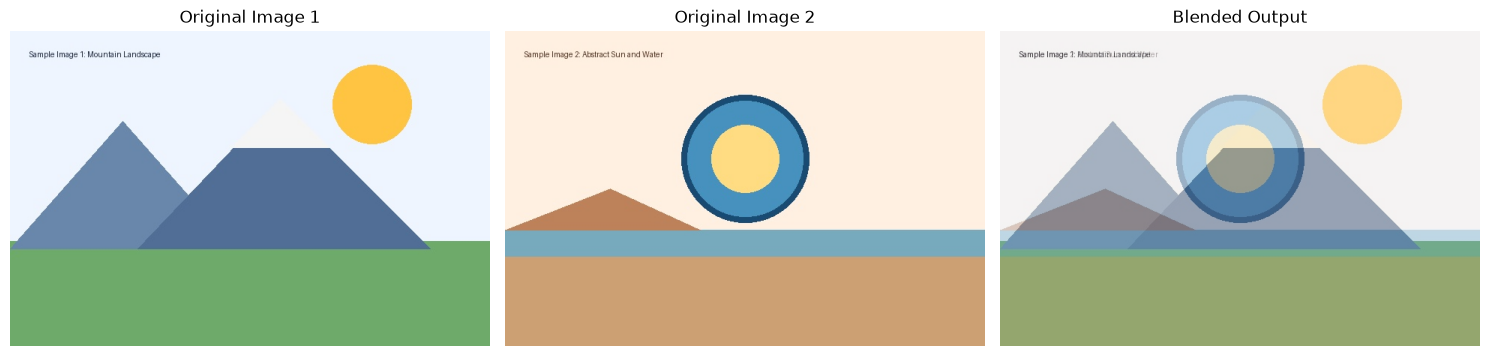

In [3]:
# OpenCV loads images in BGR format; convert to RGB for correct Matplotlib display.
images = [
    ("Original Image 1", cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)),
    ("Original Image 2", cv2.cvtColor(image2_resized, cv2.COLOR_BGR2RGB)),
    ("Blended Output", cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "exercise2_comparison.png", dpi=150)
plt.show()